# LankaEcon – Phase 5: Anomaly Detection

**Goal:** find unusual months in Sri Lankan macro, commodity and fuel series, then sort them into **real economic shocks** and **data artifacts**.

**Detectors** (`src/anomalies.py`)
| Detector | What it scores | Leakage |
|---|---|---|
| STL residual z | Residual after removing trend and seasonality (STL, period 12) from the log price; centred rolling median for non-seasonal series; the revision size for administered fuel prices. Scored with a median/MAD robust z, flagged at \|z\| ≥ 3.5 | **Retrospective** (two-sided smoother) |
| Isolation Forest | Causal features: 1- and 3-month log change, last month's change, deviation from the trailing 12-month median, volatility-scaled shock. Refitted every January on earlier rows only; flag threshold = 97.5th percentile of training scores | **Causal** (uses data ≤ t) |
| Change points (PELT) | Regime shifts in monthly growth and volatility (normal cost on log changes), or level steps for fuel (l2 cost on the log level) | Retrospective |

**Data rules:** missing months stay missing (STL fits over short gaps but never scores interpolated months, and the Isolation Forest drops incomplete rows). CPI is the cleaned Phase 1 series. The raw IMF CPI is scored only as a **diagnostic**. Fuel months flagged `possible_missing_revision` are excluded.

`scripts/11_detect_anomalies.py` writes all tables (~20 s). This notebook re-runs the same functions and draws the figures.

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "anomalies.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import anomalies as A

warnings.filterwarnings("ignore")
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 70)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
FIG, TAB = ROOT / "reports" / "figures", ROOT / "reports" / "tables"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 130, "axes.titleweight": "bold"})
save = lambda fig, name: fig.savefig(FIG / f"{name}.png", bbox_inches="tight")

specs = A.build_specs()
S = {s.name: s for s in specs}
sc, segs, dropped = A.score_all(specs)
sc = A.add_cross_source(sc, specs)
flagged = A.classify(sc)
eps = A.episodes(flagged)
val = A.validate_events(sc, segs, specs)
print(f"{len(specs)} series, {len(sc):,} series-months scored, {len(flagged)} flagged in {len(eps)} episodes; "
      f"change-point engine: {segs['engine'].iloc[0]}")

19 series, 2,461 series-months scored, 282 flagged in 107 episodes; change-point engine: builtin_pelt


## 1. Series and detector coverage

In [2]:
spec = pd.read_csv(TAB / "phase5_series_specs.csv")
spec[["series", "group", "first", "last", "observed_months", "missing_months", "residual_method",
      "if_model", "if_months_scored", "cpd_signal"]]

,series,group,first,last,observed_months,missing_months,residual_method,if_model,if_months_scored,cpd_signal
0,CPI (cleaned),macro,2000-01,2026-08,320,0,stl,CPI,272,monthly log change (normal cost)
1,"CPI (raw IMF, diagnostic)",macro,2000-01,2026-08,320,0,stl,CPI,272,monthly log change (normal cost)
2,LKR/USD,macro,2000-01,2026-10,322,0,rolling_median,LKR/USD,274,monthly log change (normal cost)
3,Brent (USD/bbl),macro,2000-01,2026-10,322,0,rolling_median,Brent,274,monthly log change (normal cost)
4,Rice (white),staple,2006-07,2026-11,234,11,stl,Rice (white),186,monthly log change (normal cost)
5,Coconut,staple,2020-01,2026-11,63,20,stl,recent_commodity,35,monthly log change (normal cost)
6,Lentils,staple,2020-01,2026-11,61,22,rolling_median,recent_commodity,35,monthly log change (normal cost)
7,Onions (imported),staple,2020-01,2026-11,71,12,rolling_median,recent_commodity,35,monthly log change (normal cost)
8,Wheat flour,staple,2004-01,2022-06,221,1,rolling_median,Wheat flour,174,monthly log change (normal cost)
9,Sugar (CBSL),staple,2023-01,2026-11,47,0,rolling_median,recent_commodity,35,monthly log change (normal cost)


- **Long series** (CPI, LKR/USD, Brent, rice, wheat flour) get their own Isolation Forest. The **2020+ commodity series** share one pooled model. WFP gaps in 2021–22 leave too few complete feature rows before 2024, so the pooled model only scores **2024 onwards**. For the crisis, these items rely on STL and change points.
- **Fuel:** the data is too gappy for the Isolation Forest (2015–18 WFP, then 2023+ DCS/CPC), so fuel uses revision-size z-scores and level change points.
- **Change points** use a built-in PELT, because `ruptures` isn't installed. `src/anomalies.py` uses `ruptures.Pelt` automatically when it is available. The built-in version is checked against an exact (unpruned) dynamic programme below.

In [3]:
rng = np.random.default_rng(1); mism = 0
for _ in range(40):
    x = np.concatenate([rng.normal(rng.normal(0, 2), rng.uniform(.5, 3), rng.integers(8, 40)) for _ in range(rng.integers(1, 5))])
    for model in ["normal", "l2"]:
        pen = 3 * np.log(len(x)) * (1 if model == "normal" else np.var(x) / 3)
        mism += A.pelt(x, model, pen, 6) != A.optimal_partition(x, model, pen, 6)
print("PELT vs exact optimal partitioning, 80 random signals: mismatches =", mism)

PELT vs exact optimal partitioning, 80 random signals: mismatches = 0


## 2. Overview: when and where anomalies occur

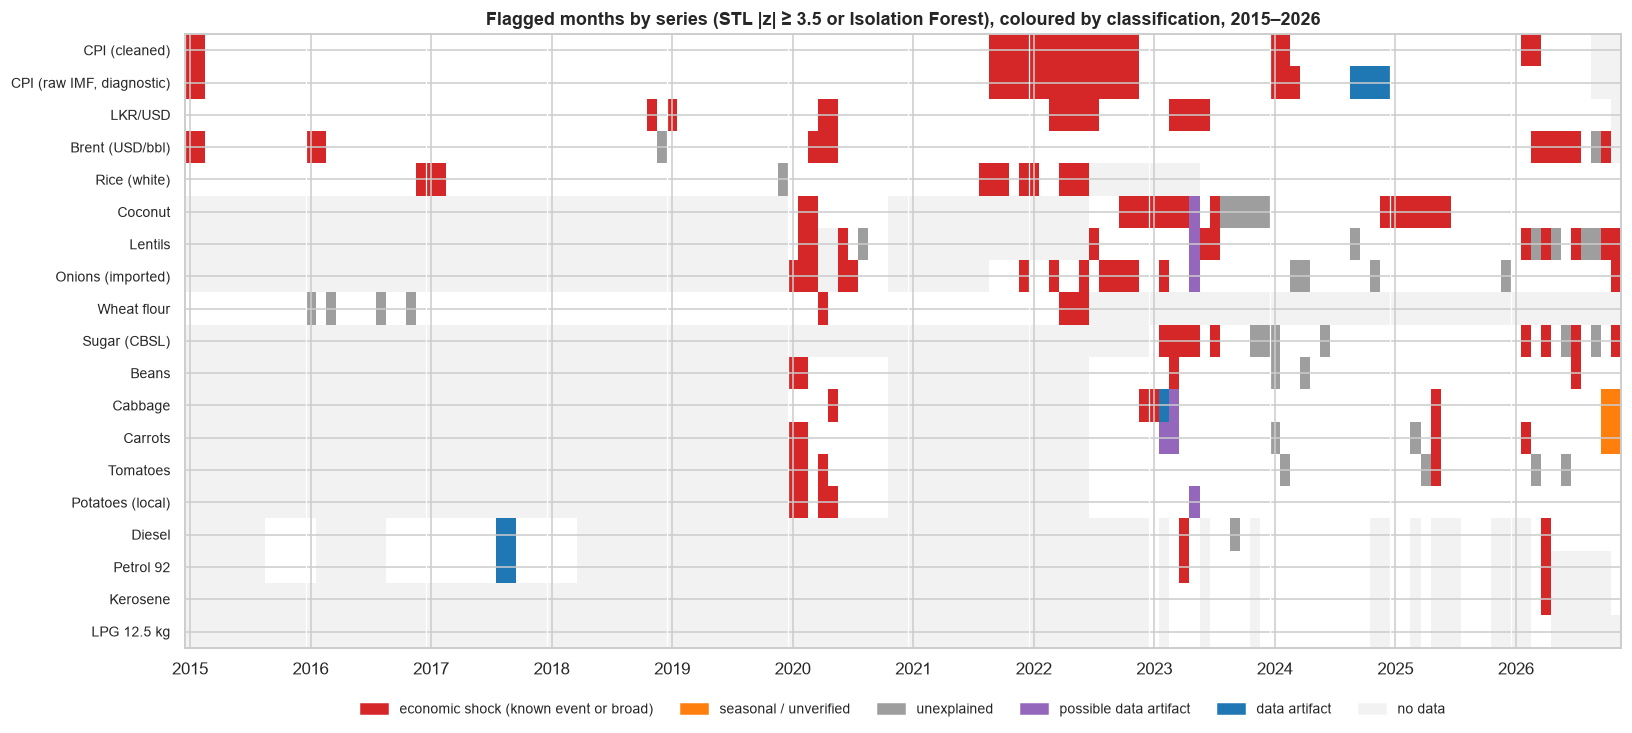

In [4]:
order = [s.name for s in specs]
cls_code = {"economic_shock": 1, "seasonal_or_unverified": 2, "unexplained": 3, "possible_data_artifact": 4,
            "possible_splice_artifact": 4, "data_artifact": 5}
grid = flagged[flagged["date"] >= "2015-01-01"].assign(c=lambda d: d["classification"].map(cls_code))
mat = grid.pivot_table(index="series", columns="date", values="c", aggfunc="max").reindex(order)
months = pd.date_range("2015-01-01", sc["date"].max(), freq="MS")
mat = mat.reindex(columns=months)
obs = sc[sc["date"] >= "2015-01-01"].pivot_table(index="series", columns="date", values="price").reindex(order).reindex(columns=months).notna()
plot = mat.fillna(0).where(obs, -1)
from matplotlib.colors import ListedColormap, BoundaryNorm
cmap = ListedColormap(["#f2f2f2", "#ffffff", "#d62728", "#ff7f0e", "#9e9e9e", "#9467bd", "#1f77b4"])
norm = BoundaryNorm([-1.5, -0.5, 0.5, 1.5, 2.5, 3.5, 4.5, 5.5], cmap.N)
fig, ax = plt.subplots(figsize=(15, 6.8))
ax.imshow(plot.values, aspect="auto", cmap=cmap, norm=norm, interpolation="none")
ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=9)
yr = [i for i, d in enumerate(months) if d.month == 1]
ax.set_xticks(yr); ax.set_xticklabels([months[i].year for i in yr])
for i in yr: ax.axvline(i - .5, color="white", lw=.8)
ax.legend(handles=[Patch(color=c, label=l) for c, l in [("#d62728", "economic shock (known event or broad)"),
          ("#ff7f0e", "seasonal / unverified"), ("#9e9e9e", "unexplained"), ("#9467bd", "possible data artifact"),
          ("#1f77b4", "data artifact"), ("#f2f2f2", "no data")]],
          loc="upper center", bbox_to_anchor=(.5, -.07), ncol=6, frameon=False, fontsize=9)
ax.set_title("Flagged months by series (STL |z| ≥ 3.5 or Isolation Forest), coloured by classification, 2015–2026")
fig.tight_layout(); save(fig, "24_anomaly_timeline")

In [5]:
summary = (flagged.groupby(["group", "classification"]).size().unstack(fill_value=0))
summary["total_flagged_months"] = summary.sum(axis=1)
summary["scored_months"] = sc.groupby("group").size()
summary

classification,data_artifact,economic_shock,possible_data_artifact,seasonal_or_unverified,unexplained,total_flagged_months,scored_months
group,,,,,,,
fuel,4,5,0,0,1,10,165
macro,4,90,0,0,13,107,1284
staple,0,79,4,0,45,128,697
vegetable,1,20,4,4,8,37,315


- **2022 crisis:** the widest red band, from late 2021 to mid-2023. It covers CPI, LKR/USD, rice, wheat flour, sugar, lentils, onion, coconut and fuel.
- **2026:** a second cluster. It spans the oil shock (fuel and LPG in April, Brent from March), CPI in Feb–Mar, and the Oct–Nov vegetable spike.
- **Unexplained (grey) flags:** mostly single months in volatile or world-price series (Brent, wheat flour, rice before 2020). These are ordinary noise above a 3.5σ cut-off, not documented events.

## 3. Data artifact vs real shock: the Sep-2024 CPI index switch

,event,series,stl_hit,if_hit,max_abs_stl_z,peak_month,outcome
58,cpi_switch_2024_09,"CPI (raw IMF, diagnostic)",True,True,5.80,2024-09,detected
59,cpi_switch_clean,CPI (cleaned),False,False,0.46,2024-10,correctly_absent


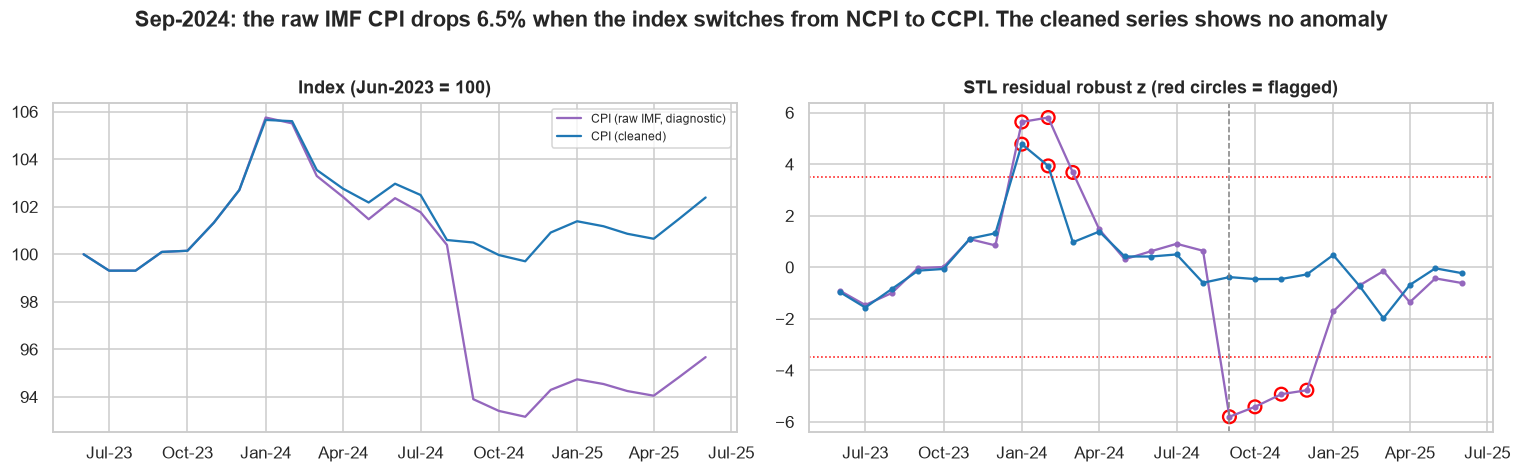

In [6]:
raw, cln = "CPI (raw IMF, diagnostic)", "CPI (cleaned)"
w = sc[sc["series"].isin([raw, cln]) & sc["date"].between("2023-06-01", "2025-06-01")]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for name, c in [(raw, "#9467bd"), (cln, "#1f77b4")]:
    d = w[w["series"] == name].set_index("date")
    axes[0].plot(d.index, 100 * (np.exp((d["log_level"] - d["log_level"].iloc[0]) / 100)), color=c, label=name)
    axes[1].plot(d.index, d["stl_z"], color=c, marker="o", ms=3, label=name)
    f = d[d["stl_flag"]]; axes[1].scatter(f.index, f["stl_z"], s=70, facecolor="none", edgecolor="red", lw=1.5)
axes[0].set_title("Index (Jun-2023 = 100)"); axes[0].legend(fontsize=8)
for y in (-A.Z_THRESH, A.Z_THRESH): axes[1].axhline(y, color="red", ls=":", lw=1)
axes[1].axvline(pd.Timestamp("2024-09-01"), color="grey", ls="--", lw=1)
axes[1].set_title("STL residual robust z (red circles = flagged)")
for ax in axes: ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
fig.suptitle("Sep-2024: the raw IMF CPI drops 6.5% when the index switches from NCPI to CCPI. The cleaned series shows no anomaly",
             fontweight="bold", y=1.02)
fig.tight_layout(); save(fig, "25_cpi_index_switch_artifact")
val[val["event"].str.startswith("cpi_switch")][["event", "series", "stl_hit", "if_hit", "max_abs_stl_z", "peak_month", "outcome"]]

- **Raw IMF CPI:** flagged in Sep-2024 by both STL (z ≈ −5.8) and the Isolation Forest. The level shift keeps the STL residual low through Dec-2024 while the trend catches up.
- **Cleaned CPI (Phase 1 chain-link):** nothing is flagged over Sep–Dec 2024 (max |z| 0.5). The Phase 1 fix removed the artifact rather than hiding a real price fall.

## 4. Data artifact vs real swing: the Feb-2023 WFP cabbage price (48 LKR/kg)

,date,series,price,r1,alt_r1,stl_z,classification,reason
2059,2022-12-01,Cabbage,107.00,-109.76,NaN,-7.37,economic_shock,crisis_2022
2060,2023-01-01,Cabbage,167.50,44.82,NaN,-4.86,economic_shock,crisis_2022
2061,2023-02-01,Cabbage,48.00,-124.98,-25.36,-11.81,data_artifact,cabbage_wfp_2023_02
2062,2023-03-01,Cabbage,160.74,120.86,14.80,-4.74,possible_data_artifact,CBSL moved +15 vs +121 (100×log)
2124,2023-02-01,Carrots,97.00,-120.14,-23.31,-11.46,possible_data_artifact,CBSL moved -23 vs -120 (100×log)
2125,2023-03-01,Carrots,203.33,74.01,-11.65,-4.66,possible_data_artifact,CBSL moved -12 vs +74 (100×log)


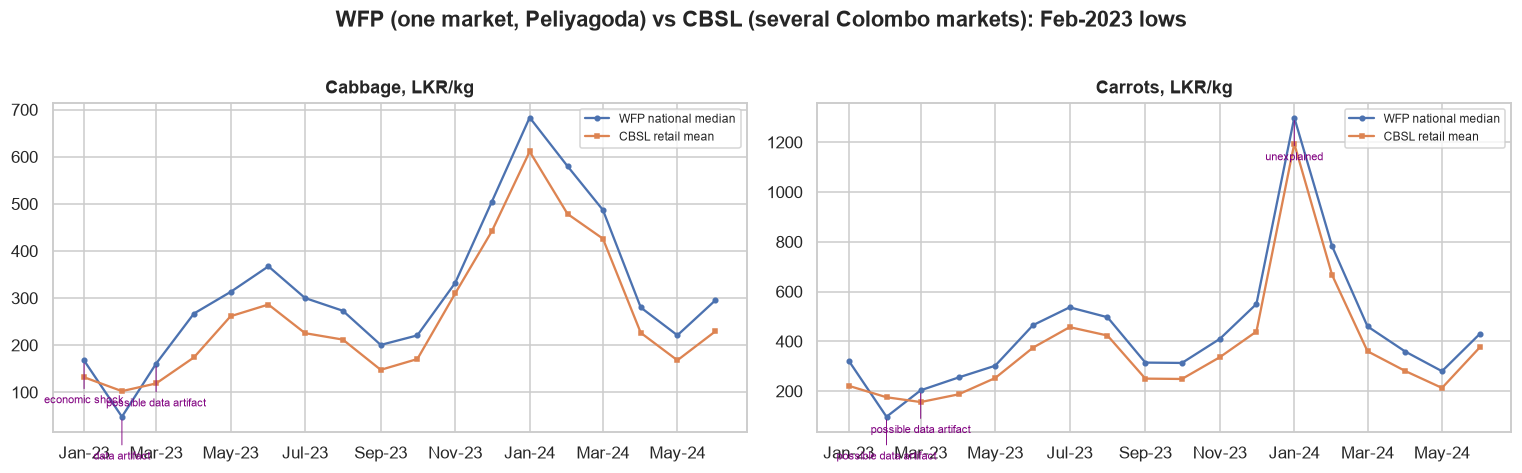

In [7]:
ov = pd.read_csv(ROOT / "data" / "processed" / "wfp_cbsl_overlap_monthly.csv", parse_dates=["date"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharex=True)
for ax, item in zip(axes, ["Cabbage", "Carrots"]):
    o = ov[(ov["commodity"] == item) & (ov["date"] <= "2024-06-01")].set_index("date")
    ax.plot(o.index, o["wfp_national"], marker="o", ms=3, label="WFP national median")
    ax.plot(o.index, o["cbsl_retail_mean"], marker="s", ms=3, label="CBSL retail mean")
    f = flagged[(flagged["series"] == item) & flagged["date"].between("2022-11-01", "2024-06-01")]
    for _, r in f.iterrows():
        ax.annotate(r["classification"].replace("_", " "), (r["date"], r["price"]), xytext=(0, -28),
                    textcoords="offset points", ha="center", fontsize=7, color="purple",
                    arrowprops=dict(arrowstyle="-", color="purple", lw=.6))
    ax.set_title(f"{item}, LKR/kg"); ax.legend(fontsize=8)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
fig.suptitle("WFP (one market, Peliyagoda) vs CBSL (several Colombo markets): Feb-2023 lows", fontweight="bold", y=1.02)
fig.tight_layout(); save(fig, "26_wfp_cbsl_cross_check")
flagged[flagged["series"].isin(["Cabbage", "Carrots"]) & flagged["date"].between("2022-11-01", "2023-04-01")][
    ["date", "series", "price", "r1", "alt_r1", "stl_z", "classification", "reason"]]

- **Cabbage, Feb-2023:** WFP falls from 168 to 48 LKR/kg (−71%; −125 in 100×log units), while CBSL retail falls only 23% (132 → 102). The dip was real, but the size of the WFP value is a **single-market artifact**. It is listed in the event catalogue and classified `data_artifact`.
- **Carrots, the same month:** the same pattern, with WFP −120 vs CBSL −23. It's caught automatically by the **cross-source rule** (`possible_data_artifact`). A month counts as unconfirmed when CBSL moves in the opposite direction, or by less than a third as much.
- **Mar-2023 cabbage and carrot rebounds:** also unconfirmed by CBSL, so they're classified as possible artifacts. **Dec-2022/Jan-2023 cabbage** lies inside the crisis window and is labelled as such, though the WFP series is single-market there too.

## 5. Regime shifts: change points in inflation, the exchange rate and prices

,series,signal,start,end,n_obs,mean,sd,missing_months_before
0,CPI (cleaned),dlog,2000-02,2005-01,60,0.82,1.84,0
1,CPI (cleaned),dlog,2005-02,2006-03,14,0.57,0.36,0
2,CPI (cleaned),dlog,2006-04,2008-06,27,1.58,0.94,0
3,CPI (cleaned),dlog,2008-07,2021-09,159,0.40,0.94,0
4,CPI (cleaned),dlog,2021-10,2022-09,12,4.55,3.11,0
5,CPI (cleaned),dlog,2022-10,2026-08,47,0.22,0.96,0
12,LKR/USD,dlog,2000-02,2002-04,27,1.01,1.30,0
13,LKR/USD,dlog,2002-05,2003-08,16,0.06,0.14,0
14,LKR/USD,dlog,2003-09,2005-01,17,0.12,1.76,0
15,LKR/USD,dlog,2005-02,2006-07,18,0.28,0.18,0


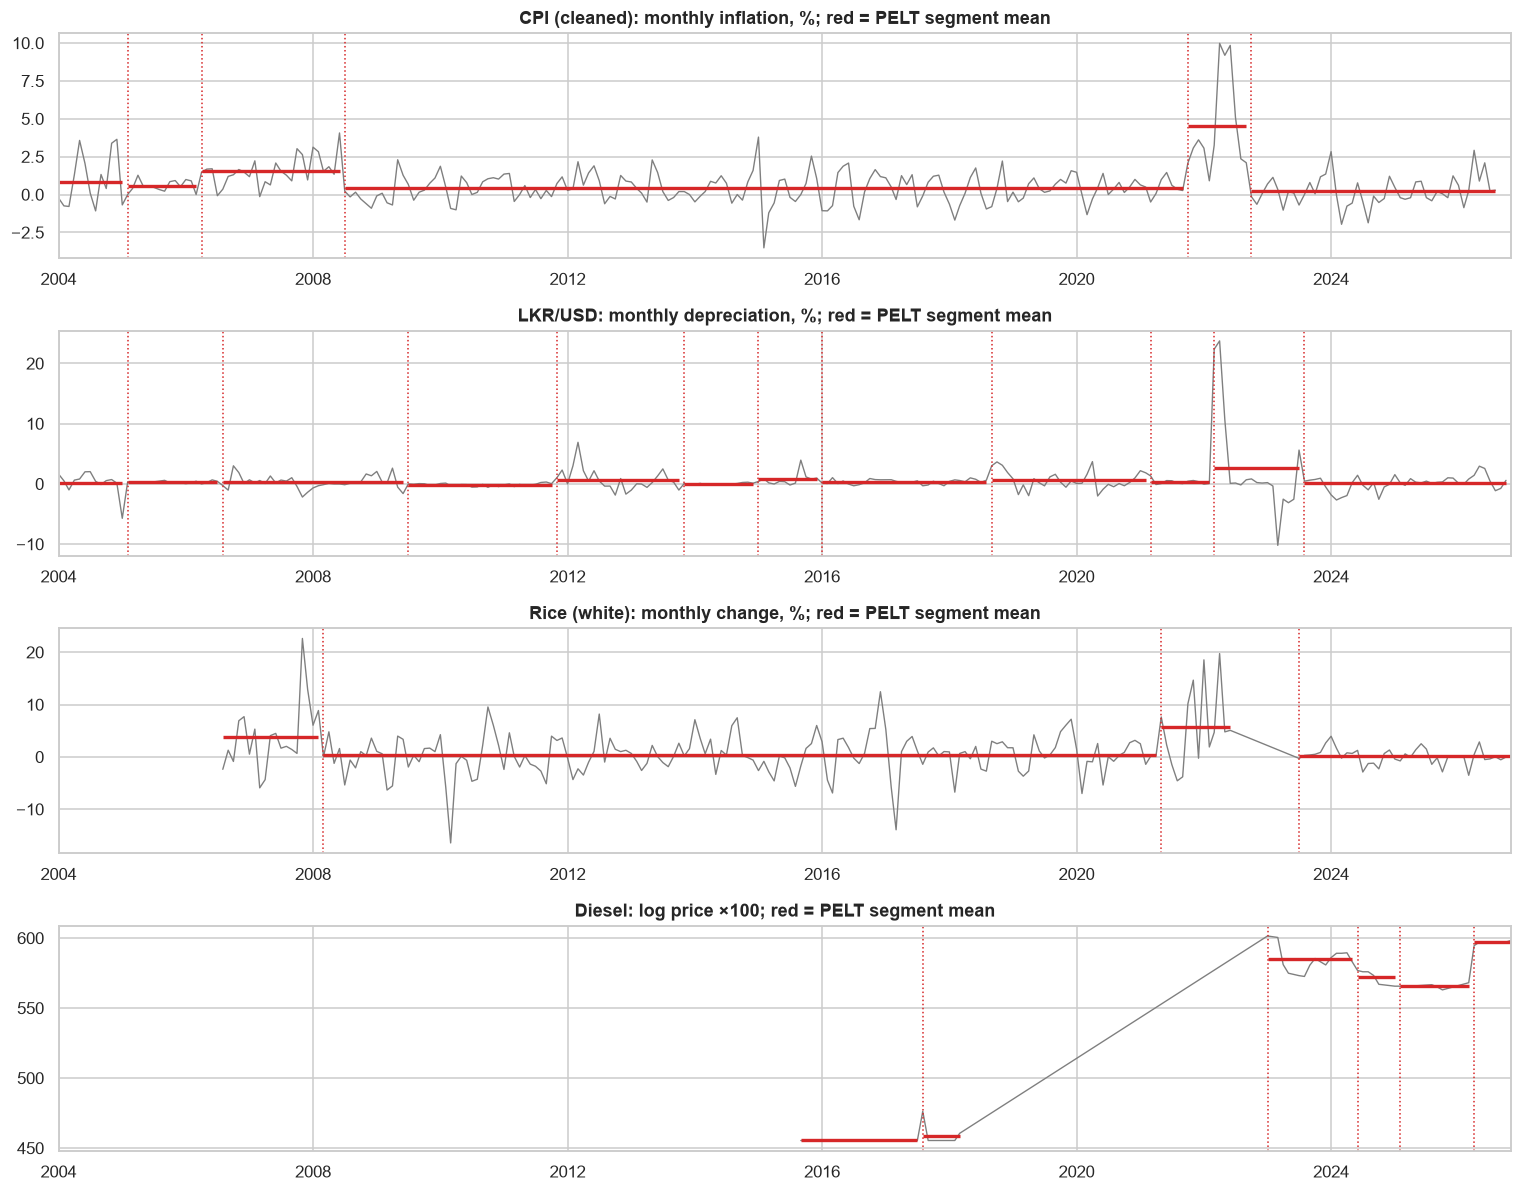

In [8]:
show = [("CPI (cleaned)", "monthly inflation, %"), ("LKR/USD", "monthly depreciation, %"),
        ("Rice (white)", "monthly change, %"), ("Diesel", "log price ×100")]
fig, axes = plt.subplots(len(show), 1, figsize=(14, 11), sharex=False)
for ax, (name, lab) in zip(axes, show):
    s = S[name]; y = A.lp(s.y)
    sig = (y.diff() if s.cpd == "dlog" else y).dropna()
    ax.plot(sig.index, sig.values, color="#7f7f7f", lw=.9)
    for _, g in segs[segs["series"] == name].iterrows():
        ax.hlines(g["mean"], g["start"], g["end"], color="#d62728", lw=2.2)
        if g["is_break"]: ax.axvline(g["start"], color="#d62728", ls=":", lw=1)
    ax.set_title(f"{name}: {lab}; red = PELT segment mean"); ax.set_xlim(pd.Timestamp("2004-01-01"), sc["date"].max())
fig.tight_layout(); save(fig, "27_change_points")
cp = segs[segs["series"].isin(["CPI (cleaned)", "LKR/USD", "Rice (white)", "Wheat flour", "Sugar (CBSL)", "Diesel", "Petrol 92"])]
cp.assign(start=cp["start"].dt.strftime("%Y-%m"), end=cp["end"].dt.strftime("%Y-%m"))[
    ["series", "signal", "start", "end", "n_obs", "mean", "sd", "missing_months_before"]]

- **CPI:** six segments. There's a 2006-04 → 2008-06 high-inflation phase (≈1.6% a month), then a long calm stretch from 2008-07 to 2021-09 (≈0.4% a month). The **crisis regime runs 2021-10 → 2022-09** (4.5% a month on average, sd 3.1), and the calm since 2022-10 averages ≈0.2% a month.
- **LKR/USD:** alternates between peg-like regimes with near-zero volatility and adjustment episodes. The biggest break is **2022-03**: the float, averaging +2.7% a month with sd 8.5. A post-crisis regime starts in **2023-08**.
- **Rice:** the 2006–08 food-price regime (+3.8% a month), then a **2021-05 → 2022-06** regime of fast rises. It begins with the fertiliser ban and runs through the crisis, averaging +5.7% a month. A calm regime (+0.1% a month) follows from 2023-07, after the 12-month data gap.
- **Diesel (level):** steps in 2023 (crisis-era pricing), a 2024–25 easing, then the **2026-04** step from the oil shock. The 2023-01 break follows a 57-month data gap (2018-04 → 2022-12), so it shows the change *across* the gap, not a dated event. The 2017-08 break comes from the WFP diesel/petrol swap (section 10): a data artifact also shows up as a regime break.

## 6. Seasonality: Maha and Yala harvests, and which vegetable swings are normal

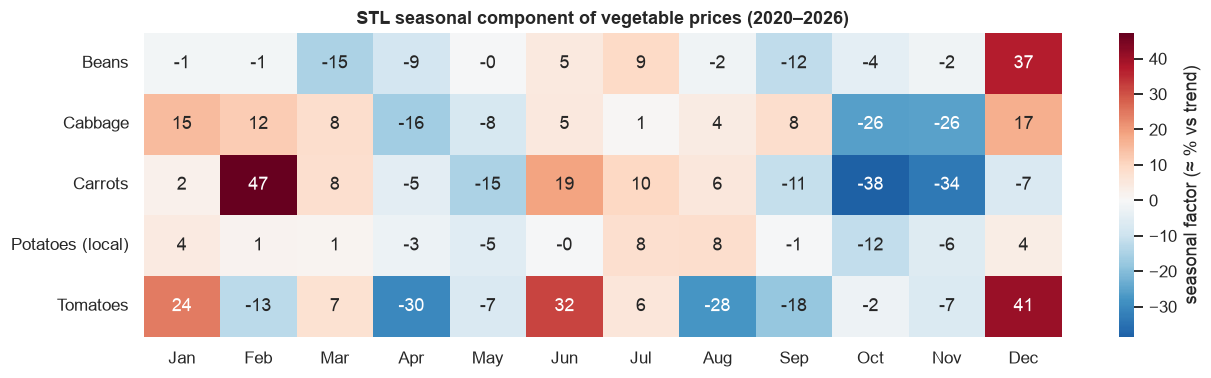

In [9]:
prof = A.seasonal_profile(sc, "vegetable")
fig, ax = plt.subplots(figsize=(12, 3.6))
sns.heatmap(prof, cmap="RdBu_r", center=0, annot=True, fmt=".0f", cbar_kws={"label": "seasonal factor (≈ % vs trend)"}, ax=ax)
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_xlabel(""); ax.set_ylabel("")
ax.set_title("STL seasonal component of vegetable prices (2020–2026)")
fig.tight_layout(); save(fig, "28_vegetable_seasonality")

- **What STL removes:** the usual seasonal swings in up-country vegetables.
  - **December peak:** beans +37, tomatoes +41, cabbage +17. This is the north-east monsoon and the end of the Yala supply.
  - **Oct–Nov trough** for cabbage and carrots: −26 to −39.
  - Tomatoes are bimodal (Jan and Jun peaks).
- **Moves the size of these swings are *not* anomalies.** Only residuals outside this pattern are flagged.
- **Rice and coconut** have small seasonal factors (±4 and ±10). Rice prices are lowest in Apr–Jun, after the Maha harvest (Feb–Mar), and highest in Dec–Jan before it.

## 7. Weather and supply shocks in 2025–26: Cyclone Ditwah and the Oct–Nov 2026 spike

December month-on-month change (100×log) by year:


,Dec-2022,Dec-2023,Dec-2024,Dec-2025
Beans,43,13,19,74
Cabbage,-110,42,37,55
Carrots,-69,29,36,35
Tomatoes,-43,75,31,98
Potatoes (local),11,7,9,21


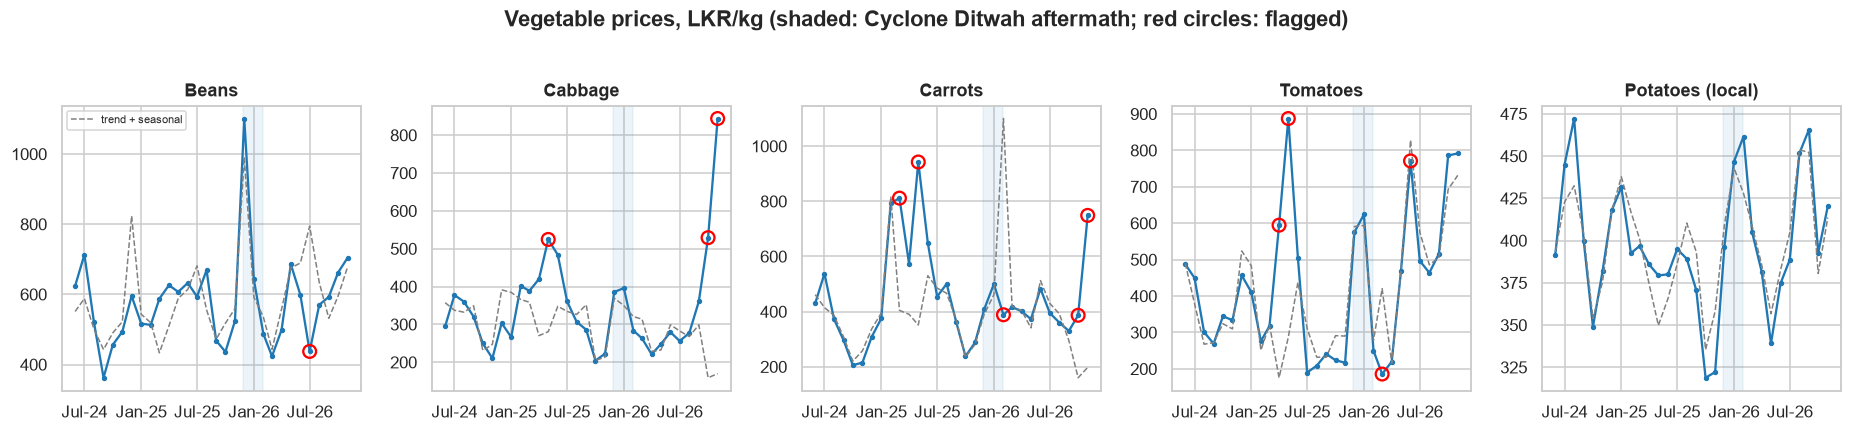

In [10]:
items = ["Beans", "Cabbage", "Carrots", "Tomatoes", "Potatoes (local)"]
fig, axes = plt.subplots(1, len(items), figsize=(17, 3.8))
for ax, n in zip(axes, items):
    d = sc[(sc["series"] == n) & (sc["date"] >= "2024-06-01")].set_index("date")
    ax.plot(d.index, d["price"], color="#1f77b4", marker="o", ms=2.5)
    ax.plot(d.index, np.exp((d["trend"] + d["seasonal"]) / 100), color="grey", ls="--", lw=1, label="trend + seasonal")
    f = d[d["anomaly"]]; ax.scatter(f.index, f["price"], s=70, facecolor="none", edgecolor="red", lw=1.5, zorder=3)
    ax.axvspan(pd.Timestamp("2025-11-27"), pd.Timestamp("2026-01-31"), color="#1f77b4", alpha=.08)
    ax.set_title(n); ax.xaxis.set_major_locator(mdates.MonthLocator([1, 7])); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
axes[0].legend(fontsize=7)
fig.suptitle("Vegetable prices, LKR/kg (shaded: Cyclone Ditwah aftermath; red circles: flagged)", fontweight="bold", y=1.03)
fig.tight_layout(); save(fig, "29_vegetables_2025_2026")

dec = {}
for n in items:
    y = S[n].y; r = 100 * np.log(y).diff()
    dec[n] = {f"Dec-{d:%Y}": round(v) for d, v in r[r.index.month == 12].dropna().items()}
print("December month-on-month change (100×log) by year:")
pd.DataFrame(dec).T

- **Cyclone Ditwah (landfall 27–28 Nov 2025):** Dec-2025 was the **largest December rise on record** for beans (+74) and tomatoes (+98), and cabbage and potato also rose more than in earlier Decembers. Even so, the shock falls **within the normal December seasonal peak**:
  - STL |z| ≤ 1.9 for every vegetable except carrots.
  - Isolation Forest percentiles reached 0.95 for beans and tomatoes, just under the 0.975 cut-off.
  - Carrots are flagged in Feb-2026, when prices fell back faster than usual.

  The detectors therefore **under-detect** a weather shock that lands in the peak season. A seasonal-difference check (Dec vs earlier Decembers) separates it better.
- **Oct–Nov 2026:** cabbage (z 6.8 → 9.0) and carrots (6.0 → 9.1) are strongly flagged, because they rose in months that are normally their seasonal **trough**. Two caveats apply:
  - the cause isn't verified;
  - these are the last two months of the series, where a two-sided STL is least reliable, and Nov-2026 covers CBSL reports only up to 25 Nov.

  They're classified `seasonal_or_unverified`, not as a confirmed shock.

## 8. 2026 oil shock: fuel, CPI and the exchange rate

,series,stl_hit,if_hit,cp_hit,max_abs_stl_z,peak_month,outcome
74,CPI (cleaned),True,False,False,5.45,2026-03,detected
75,LKR/USD,False,False,False,2.79,2026-06,missed
76,Brent (USD/bbl),True,True,False,5.27,2026-07,detected
77,Diesel,True,False,True,13.23,2026-04,detected
78,Petrol 92,True,False,False,13.01,2026-04,detected
79,Kerosene,True,False,False,4.63,2026-04,detected
80,LPG 12.5 kg,False,False,False,2.92,2026-04,missed


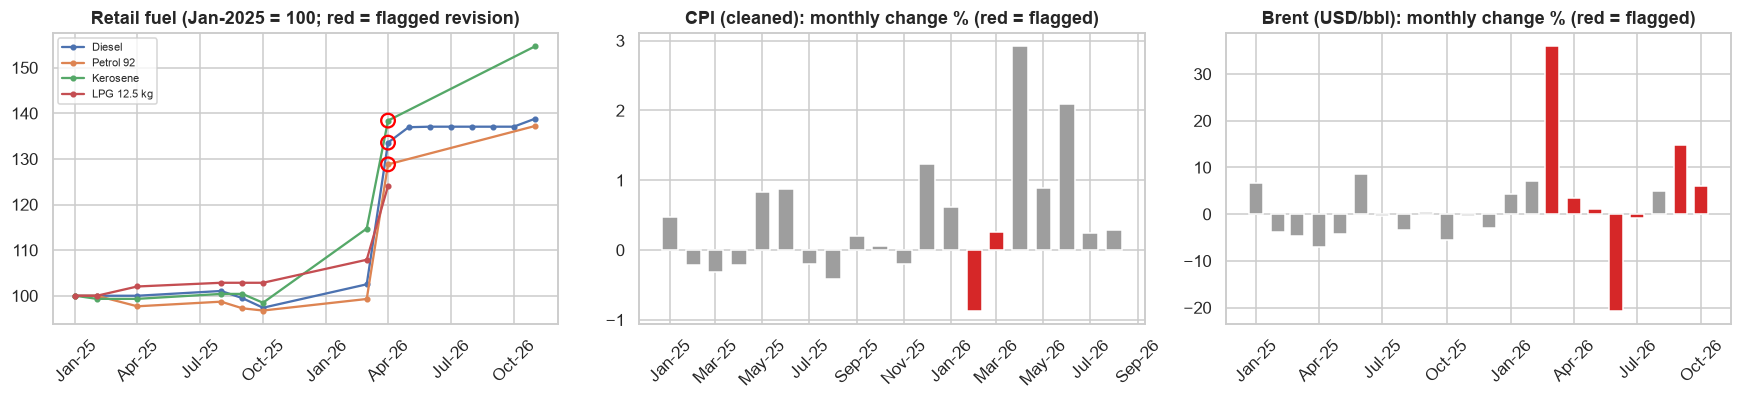

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for prod in ["Diesel", "Petrol 92", "Kerosene", "LPG 12.5 kg"]:
    d = sc[(sc["series"] == prod) & (sc["date"] >= "2025-01-01")].set_index("date")
    base = d["price"].iloc[0]
    axes[0].plot(d.index, 100 * d["price"] / base, marker="o", ms=3, label=prod)
    f = d[d["stl_flag"]]; axes[0].scatter(f.index, 100 * f["price"] / base, s=80, facecolor="none", edgecolor="red", lw=1.5, zorder=3)
axes[0].set_title("Retail fuel (Jan-2025 = 100; red = flagged revision)"); axes[0].legend(fontsize=7)
for ax, name in zip(axes[1:], ["CPI (cleaned)", "Brent (USD/bbl)"]):
    d = sc[(sc["series"] == name) & (sc["date"] >= "2025-01-01")].set_index("date")
    ax.bar(d.index, d["r1"], width=20, color=np.where(d["anomaly"], "#d62728", "#9e9e9e"))
    ax.set_title(f"{name}: monthly change % (red = flagged)")
for ax in axes: ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y")); ax.tick_params(axis="x", rotation=45)
fig.tight_layout(); save(fig, "30_oil_shock_2026")
val[val["event"] == "fuel_2026"][["series", "stl_hit", "if_hit", "cp_hit", "max_abs_stl_z", "peak_month", "outcome"]]

- **Fuel:** the March 2026 hikes (+8% on 9–10 Mar, +25% on 21–22 Mar, both tied to the Middle East conflict) appear as **April** jumps in the monthly averages. Diesel (z 13.2), petrol 92 (13.0) and kerosene (4.6) are flagged, and diesel has a level change point in 2026-04. LPG's April step (+14%) is just under the threshold (z 2.9). Months flagged `possible_missing_revision` (petrol, kerosene May–Oct 2026) are excluded, so later 2026 steps can't be dated reliably.
- **CPI:** +3.0% in Apr-2026 (the largest monthly rise since the crisis) and +2.1% in Jun-2026, yet the STL flags fall in **Feb–Mar** with *negative* z. The two-sided trend starts rising before the April jump, which pushes Feb–Mar residuals down. **This is a side effect of the smoother, not a price fall.** For monthly inflation shocks, rely on the causal Isolation Forest and the change-point regime.
- **LKR/USD** depreciated ~7% from Mar to Jun 2026 (312 → 334). Gradual moves like this stay under every threshold.

## 9. Validation against the event catalogue

In [12]:
ev = A.events_table()
ev[["id", "name", "start", "end", "kind", "expect", "source"]]

,id,name,start,end,kind,expect,source
0,tsunami_2004,Indian Ocean tsunami,2004-12,2005-02,economic_shock,detect,background
1,global_2008,Global food and oil price spike,2007-10,2008-10,economic_shock,detect,background
2,floods_2011,Floods hit the Maha paddy harvest,2011-01,2011-06,weather_shock,detect,background
3,lkr_2012,LKR allowed to depreciate,2012-02,2012-04,policy,detect,background
4,price_cuts_2015,Post-election price cuts,2015-01,2015-02,policy,detect,background
5,drought_2016_17,2016–17 drought,2016-10,2017-06,weather_shock,detect,background
6,oil_2014_16,Oil price collapse,2014-11,2016-02,economic_shock,detect,background
7,political_2018,Oct–Dec 2018 constitutional crisis,2018-10,2018-12,policy,detect,background
8,covid,COVID-19 lockdowns,2020-03,2020-06,economic_shock,detect,project
9,fertiliser_ban,Chemical fertiliser import ban,2021-05,2021-12,policy,detect,background


outcome
detected            56
missed              15
not_flagged         12
flagged              2
correctly_absent     1


,event,series,max_abs_stl_z,peak_month,if_scored
4,global_2008,LKR/USD,2.97,2007-09,True
12,drought_2016_17,CPI (cleaned),1.52,2017-04,True
16,covid,CPI (cleaned),1.58,2020-02,True
17,covid,"CPI (raw IMF, diagnostic)",1.57,2020-02,True
20,covid,Rice (white),1.38,2020-03,True
34,crisis_2022,Brent (USD/bbl),3.08,2021-12,True
44,crisis_2022,Tomatoes,3.44,2022-12,False
48,crisis_2022,Kerosene,1.50,2023-04,False
49,crisis_2022,LPG 12.5 kg,3.39,2023-04,False
69,ditwah,Beans,0.79,2025-12,True


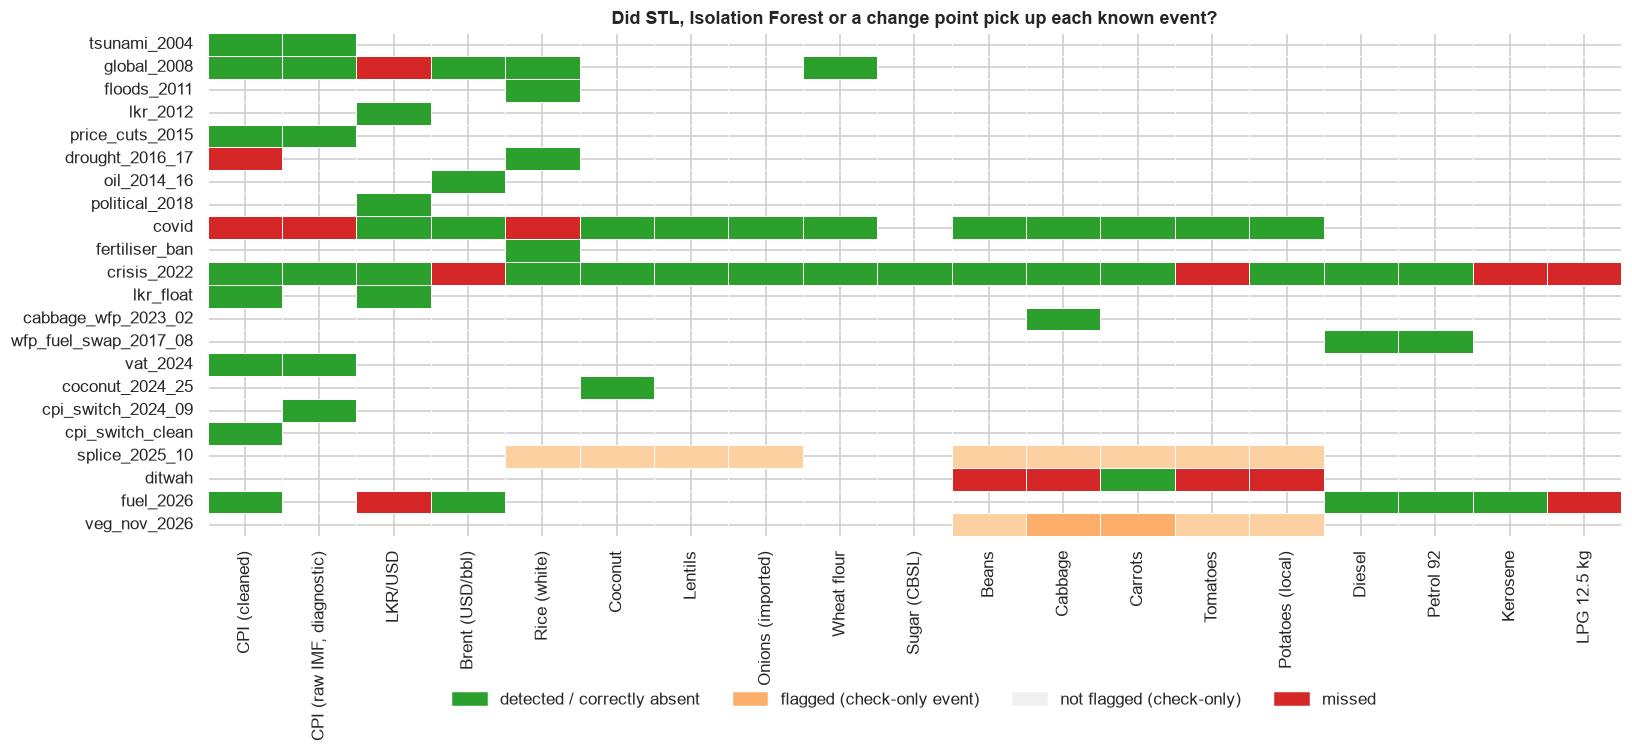

In [13]:
mat = val.assign(hit=val["outcome"].map({"detected": 2, "correctly_absent": 2, "flagged": 1, "missed": -1,
                                         "not_flagged": 0, "false_alarm": -2}))
piv = mat.pivot_table(index="event", columns="series", values="hit", aggfunc="max")
piv = piv.reindex([e.id for e in A.EVENTS]).reindex(columns=[s.name for s in specs]).dropna(how="all", axis=1)
fig, ax = plt.subplots(figsize=(15, 7))
cmap = ListedColormap(["#d62728", "#fdd0a2", "#f0f0f0", "#fdae6b", "#2ca02c"])
sns.heatmap(piv, cmap=cmap, vmin=-1.5, vmax=2.5, linewidths=.5, linecolor="white", cbar=False, ax=ax,
            mask=piv.isna())
ax.set_xlabel(""); ax.set_ylabel("")
ax.legend(handles=[Patch(color="#2ca02c", label="detected / correctly absent"), Patch(color="#fdae6b", label="flagged (check-only event)"),
                   Patch(color="#f0f0f0", label="not flagged (check-only)"), Patch(color="#d62728", label="missed")],
          loc="upper center", bbox_to_anchor=(.5, -.28), ncol=4, frameon=False)
ax.set_title("Did STL, Isolation Forest or a change point pick up each known event?")
fig.tight_layout(); save(fig, "31_event_validation")
print(val["outcome"].value_counts().to_string())
val[val["outcome"] == "missed"][["event", "series", "max_abs_stl_z", "peak_month", "if_scored"]]

- **Expected-to-detect events:** 56 of 71 event–series pairs are detected. Every major macro event is caught:
  - the 2008 global spike (CPI, rice, wheat, Brent)
  - the 2015 price cuts
  - the 2018 political crisis (FX)
  - COVID (FX, Brent, most food)
  - the fertiliser ban (rice)
  - the 2022 crisis (15 of 19 series)
  - the 2024 VAT rise
  - the 2026 oil shock (CPI, Brent, three of four fuels)
- **What gets missed** is small or gradual moves:
  - COVID in CPI and rice: both barely moved.
  - The 2016–17 drought in CPI.
  - Gradual FX depreciation.
  - LPG, kerosene and tomato crisis moves just under the cut-off.
  - The Ditwah vegetable spike, which sits on the seasonal peak (section 7).
- **The CPI index switch** is detected in the raw series and **correctly absent** from the cleaned one.
- **WFP→CBSL splice (2025-10):** no series is flagged at the splice month, so the level adjustment from Phase 2 works.

## 10. Episodes that are not known events

In [14]:
e = eps[eps["classification"] != "economic_shock"].copy()
e["start"], e["end"] = e["start"].dt.strftime("%Y-%m"), e["end"].dt.strftime("%Y-%m")
e[["series", "start", "end", "months_flagged", "peak_stl_z", "if_months", "classification", "reason", "edge_of_series"]]

,series,start,end,months_flagged,peak_stl_z,if_months,classification,reason,edge_of_series
44,Diesel,2017-08,2017-09,2,10.41,0,data_artifact,wfp_fuel_swap_2017_08,False
46,Diesel,2023-09,2023-09,1,4.02,0,unexplained,,False
74,Petrol 92,2017-08,2017-09,2,-10.41,0,data_artifact,wfp_fuel_swap_2017_08,False
5,Brent (USD/bbl),2000-04,2000-04,1,-4.87,0,unexplained,,False
6,Brent (USD/bbl),2002-11,2002-11,1,-4.12,0,unexplained,,False
7,Brent (USD/bbl),2003-02,2003-02,1,3.79,0,unexplained,,False
8,Brent (USD/bbl),2004-10,2004-10,1,3.67,1,unexplained,,False
10,Brent (USD/bbl),2008-10,2008-12,3,-3.71,3,unexplained,,False
11,Brent (USD/bbl),2012-06,2012-06,1,-4.51,0,unexplained,,False
14,Brent (USD/bbl),2018-12,2018-12,1,-3.55,0,unexplained,,False


**Data artifacts** (fix or exclude before modelling):
| Episode | Evidence | Action |
|---|---|---|
| Raw IMF CPI, Sep–Dec 2024 | NCPI→CCPI switch (Phase 1) | already fixed; use cleaned CPI |
| WFP cabbage, Feb-2023 (48 LKR/kg) | CBSL fell 23%, WFP 71% | treat WFP value as an outlier |
| WFP carrots, Feb-2023; WFP potato, onion and lentils, May-2023 | CBSL disagrees in direction or size | prefer CBSL in 2023 |
| WFP diesel/petrol, Aug-2017 | values exactly swapped vs Jul/Sep in every market (**new finding**) | swap back or drop the month |
| WFP wheat flour, Dec-2004 (68 LKR/kg) | +54 then −66 in a smooth, importer-set price | likely a data error |

**Unexplained:** 36 episodes, mostly single-month flags in world prices (Brent), early WFP wheat and rice, and a few 2024–25 vegetable and onion moves that CBSL confirms in direction. These are real price moves with no catalogued cause. They are left unlabelled rather than forced onto an event.

## 11. Isolation Forest: causal scores for CPI and LKR/USD

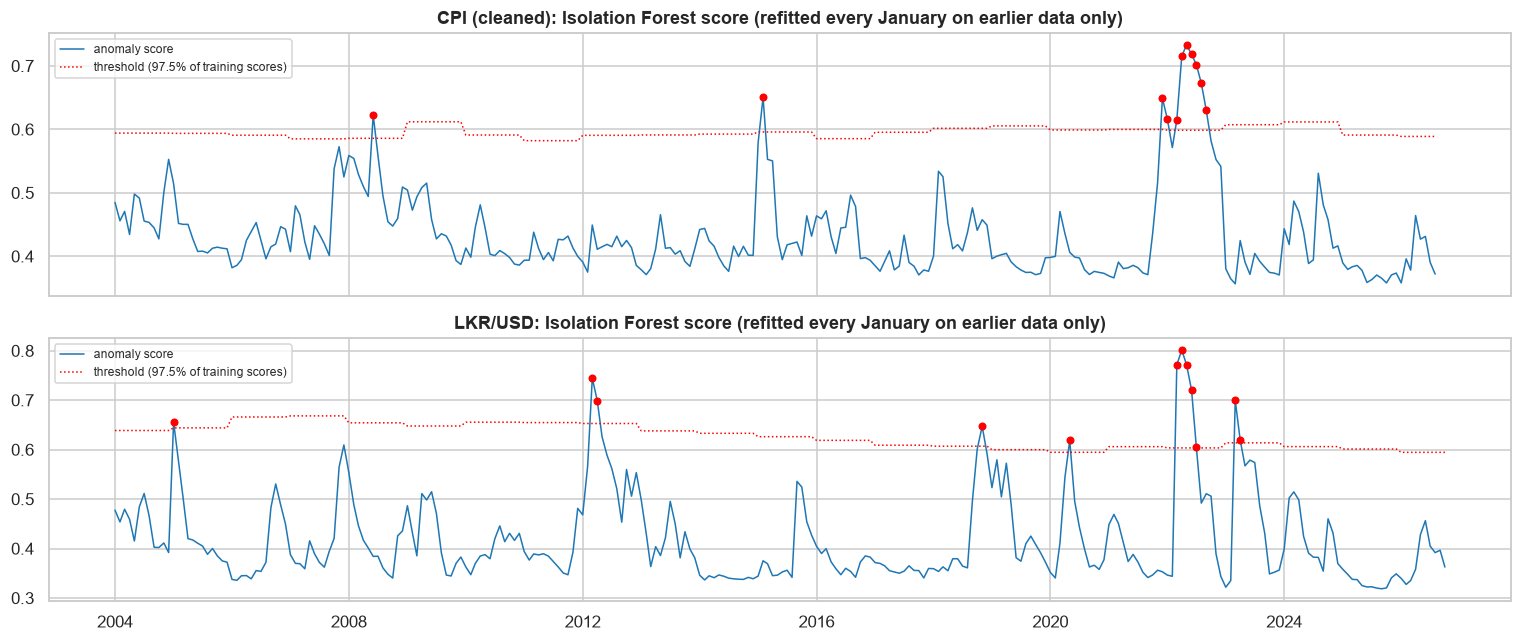

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
for ax, name in zip(axes, ["CPI (cleaned)", "LKR/USD"]):
    d = sc[sc["series"] == name].set_index("date")
    ax.plot(d.index, d["if_score"], color="#1f77b4", lw=1, label="anomaly score")
    ax.plot(d.index, d["if_threshold"], color="red", ls=":", lw=1, label="threshold (97.5% of training scores)")
    f = d[d["if_flag"]]; ax.scatter(f.index, f["if_score"], color="red", s=18, zorder=3)
    ax.set_title(f"{name}: Isolation Forest score (refitted every January on earlier data only)"); ax.legend(fontsize=8, loc="upper left")
fig.tight_layout(); save(fig, "32_isolation_forest_scores")

- **Because the Isolation Forest is causal, its flags are dated when the anomaly could first have been seen in real time.**
  - **CPI:** flags start in Dec-2021 and continue through Sep-2022.
  - **LKR/USD:** flags Mar–Jul 2022, the float, then the 2023 appreciation.
- **Thresholds stay at about 0.59–0.61** because each one is a quantile of that year's training scores. The caveat is that crisis months are now in the training data, so a repeat of 2022 could look less isolated than the first crisis did. Read the scores alongside the STL and change-point results.